# Recherche : L'effet jour de la semaine (Day-of-Week) sur ETFs liquides

Notebook de recherche **standalone** de la série QuantConnect : données publiques
`yfinance`, exécution locale, **aucun** passage par QC Cloud.

L'anomalie *day-of-the-week* (DOW) est l'une des plus anciennes de la littérature
de calendrier : certains jours de la semaine (le **Lundi** en tête, souvent en
association avec l'effet *turn-of-the-month*) afficheraient des rendements moyens
systématiquement supérieurs ou inférieurs aux autres jours (Reling & Ritter 2000 ;
littérature DOW antérieure). La question que ce carnet pose, de façon **falsifiable** :

1. L'effet **brut** existe-t-il encore sur des ETFs index liquides modernes ?
2. Une stratégie **nette de coûts** (long le jour canonique, à plat sinon) bat-elle
   le *Buy & Hold* en Sharpe / CAGR / MaxDD ?
3. Le « meilleur jour » est-il **stable** out-of-sample (walk-forward) — sinon le
   signal n'est pas tradeable.
4. Test de **Diebold-Mariano** out-of-sample : la supériorité est-elle significative ?

Le verdict est **honnête** (`BEATS` / `NO BEATS` / `INCONCLUSIVE`) : un résultat nul
documenté est un livrable à part entière (fil rouge de la série, cf. le verdict
M12-HF du README).

> **Rappel** : les données `yfinance` (gratuites) ont des limites (ajustements,
> splits, profondeur). Un edge confirmé ici devra être re-validé sur QC Cloud avant
> toute conclusion de robustesse.

**Navigation** : [Index recherche](README.md) | [<< intraday_volume_periodicity](intraday_volume_periodicity.ipynb)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from math import erf, sqrt

# --- Paramètres de recherche ---
TICKERS  = ["SPY", "QQQ", "EFA"]   # ETFs index liquides (S&P500 / Nasdaq100 / MSCI EAFE)
START    = "2010-01-01"            # horizon de mesure
COST_BPS = 10                      # coût de transition (10 bps / passage long<->flat), comme dans la série
DOW_NAMES = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]

print("Env local : yfinance", yf.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)
print("Actifs :", TICKERS, "| horizon depuis", START, "| coût/transition", COST_BPS, "bps")


Env local : yfinance 1.2.0 | pandas 3.0.2 | numpy 2.4.2
Actifs : ['SPY', 'QQQ', 'EFA'] | horizon depuis 2010-01-01 | coût/transition 10 bps


## 1. Chargement des données

On télécharge les **clôtures ajustées** (`auto_adjust=True`) des trois ETFs, un par
un. Le téléchargement séquentiel évite l'ambiguïté de l'index Multi-colonnes que
`yfinance` produit selon les versions quand on demande plusieurs tickers d'un coup.

In [2]:
def load_prices(tickers, start=START):
    """Clôtures ajustées d'une liste d'ETFs, un par un.
    Renvoie un DataFrame [date] -> {ticker: close} aligné (dropna)."""
    cols = {}
    for t in tickers:
        df = yf.download(t, start=start, auto_adjust=True, progress=False)
        if df is None or df.empty:
            raise ValueError("aucune donnée pour " + t)
        close = df["Close"]
        if isinstance(close, pd.DataFrame):
            close = close.iloc[:, 0]
        cols[t] = close
    return pd.DataFrame(cols).dropna()

prices = load_prices(TICKERS)
print("Clôtures chargées :", prices.shape)
print("Période :", prices.index[0].date(), "->", prices.index[-1].date())
prices.tail(3)


Clôtures chargées : (4228, 3)
Période : 2010-01-04 -> 2026-10-23


,SPY,QQQ,EFA
Date,,,
2026-10-21,773.090027,725.200012,104.059998
2026-10-22,763.960022,704.469971,103.150002
2026-10-23,759.969971,704.400024,102.629997


## 2. Classification par jour de la semaine (sans regard dans le futur)

Le jour de la semaine de chaque observation est lu **directement sur sa date**
(`index.dayofweek`, `0 = Lundi`). C'est une information purement calendaire :
elle ne dépend d'aucune valeur future, donc **pas de lookahead** à ce stade.
On travaille ici sur **SPY** (le plus liquide de l'univers) pour l'effet brut.

In [3]:
# Rendements quotidiens de SPY
spy = prices["SPY"]
ret = spy.pct_change().dropna()
dow = pd.Series(ret.index.dayofweek, index=ret.index)   # 0=Lundi ... 6=Dimanche

# Effet BRUT par jour de la semaine : moyenne des rendements, en bps/jour
raw = ret.groupby(dow).mean() * 1e4
cnt = ret.groupby(dow).count()
tab = pd.DataFrame({"bps_par_jour": raw.round(2), "n_observations": cnt})
tab.index = [DOW_NAMES[i] for i in tab.index]
# Lecture : les jours de trading (Lun-Ven) seulement
tab[tab.index.isin(DOW_NAMES[:5])]


,bps_par_jour,n_observations
Lundi,6.07,790
Mardi,7.74,870
Mercredi,7.69,867
Jeudi,3.19,852
Vendredi,4.13,848


## 3. Effet brut : bps/jour par jour de la semaine

La table ci-dessus et le graphique donnent l'effet **descriptif** (moyenne sur
l'échantillon complet). C'est un diagnostic, pas encore une stratégie : choisir
le « meilleur jour » sur cet échantillon complet et le ré-tester sur le même
échantillon serait un biais de sélection (in-sample). C'est le rôle de la
section walk-forward (5) de trancher.

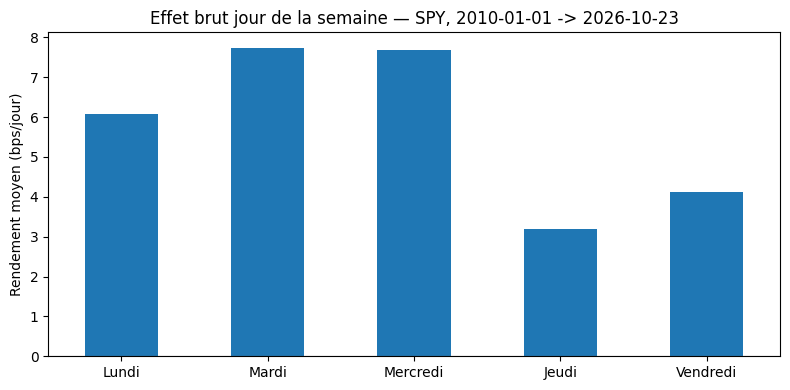

In [4]:
t = tab[tab.index.isin(DOW_NAMES[:5])]
plt.figure(figsize=(8, 4))
t["bps_par_jour"].plot(kind="bar", rot=0)
plt.axhline(0, color="grey", lw=0.8)
plt.ylabel("Rendement moyen (bps/jour)")
plt.title("Effet brut jour de la semaine — SPY, " + START + " -> " + str(prices.index[-1].date()))
plt.tight_layout()
plt.show()


## 4. Stratégie nette de coûts vs Buy & Hold

Pour poser une comparaison **sans sélection in-sample**, on utilise une règle
**pré-spécifiée** : être **long le Lundi** (le jour canonique de l'anomalie DOW),
à plat le reste de la semaine. Aucun paramètre n'est estimé sur la donnée, donc
pas de regard dans le futur. Chaque **transition** de position coûte `COST_BPS`.

In [5]:
def dow_strategy(ret, long_dow=0, cost_bps=COST_BPS):
    """Calendaire pré-spécifié : long le jour `long_dow` (0=Lundi), plat sinon.
    Coût de `cost_bps` à chaque transition de position. Renvoie (rendements, position)."""
    pos = (dow == long_dow).astype(float)
    strat_ret = pos * ret
    turns = pos.diff().abs().fillna(pos)          # 1 à chaque changement de position
    strat_ret = strat_ret - turns * (cost_bps / 1e4)
    return strat_ret, pos

def perf(ser):
    nav = (1 + ser).cumprod()
    n = len(ser)
    sharpe = ser.mean() / (ser.std() + 1e-12) * np.sqrt(252)
    cagr = nav.iloc[-1] ** (252 / n) - 1
    maxdd = (nav / nav.cummax() - 1).min()
    return pd.Series({"Sharpe": round(sharpe, 3), "CAGR": "%.2f%%" % (cagr * 100), "MaxDD": "%.2f%%" % (maxdd * 100)})

# Règle pré-spécifiée : long le Lundi (0), nette de coûts
strat_ret, pos = dow_strategy(ret, long_dow=0)
bh = ret                                    # Buy & Hold = détention continue de SPY
cmp = pd.DataFrame({"DOW long-Lundi (net)": perf(strat_ret), "Buy & Hold": perf(bh)})
cmp


,DOW long-Lundi (net),Buy & Hold
Sharpe,-0.855,0.855
CAGR,-6.63%,14.00%
MaxDD,-73.48%,-33.72%


## 5. Walk-forward 5-fold + test de Diebold-Mariano

Le cœur de la falsification. Dans **chaque** fold, le **meilleur** jour de la
semaine est choisi sur la **période d'entraînement uniquement**, puis appliqué à
la **période de test** (sans ré-estimation). Deux lectures :

- **Stabilité** : si le « meilleur jour » change de fold en fold, le signal n'est
  **pas** prédictif out-of-sample (c'est du bruit in-sample) -> pas de stratégie.
- **Diebold-Mariano** (HAC, Newey-West m=4) sur la perte quadratique, out-of-sample :
  la stratégie DOW bat-elle significativement le B&H ?

In [6]:
def walk_forward_dow(ret, dow, n_folds=5, cost_bps=COST_BPS):
    n = len(ret); fold = n // n_folds; idx = ret.index
    test_parts, chosen = [], []
    for k in range(n_folds):
        tr_end = fold * (k + 1)
        te_end = fold * (k + 2) if k + 1 < n_folds else n
        tr_s, te_s = idx[:tr_end], idx[tr_end:te_end]
        train_best = int(ret[tr_s].groupby(dow[tr_s]).mean().idxmax())
        chosen.append(DOW_NAMES[train_best])
        s, _ = dow_strategy(ret[te_s], long_dow=train_best, cost_bps=cost_bps)
        test_parts.append(s)
    return pd.concat(test_parts), chosen

def oos_bh(ret, n_folds=5):
    n = len(ret); fold = n // n_folds; idx = ret.index
    parts = [ret[idx[fold * (k + 1):(fold * (k + 2) if k + 1 < n_folds else n)]] for k in range(n_folds)]
    return pd.concat(parts)

def dm_test(a, b, m=4):
    """Diebold-Mariano HAC (Newey-West, m lags) sur la perte quadratique.
    stat > 0 => `a` a une perte quadratique moyenne plus grande que `b` (pire)."""
    d = ((a - a.mean()) ** 2) - ((b - b.mean()) ** 2)
    d = d - d.mean()
    n = len(d); var = d.var()
    for l in range(1, m + 1):
        var += 2 * np.mean(d[:-l] * d[l:])
    stat = d.mean() / np.sqrt(max(var, 1e-12) / n)
    p = 2 * (1 - 0.5 * (1 + erf(abs(stat) / sqrt(2))))
    return stat, p

oos, chosen_days = walk_forward_dow(ret, dow)
oos_bh = oos_bh(ret)
dm_stat, dm_p = dm_test(oos, oos_bh)

print("Meilleur jour par fold (entraînement) :", chosen_days)
print("Stabilité :", "STABLE (même jour)" if len(set(chosen_days)) == 1 else "INSTABLE (%d jours distincts)" % len(set(chosen_days)))
print("DM OOS : stat=%.3f, p=%.3f" % (dm_stat, dm_p))
print("OOS net  : Sharpe DOW=%.3f | B&H=%.3f" % (perf(oos)["Sharpe"], perf(oos_bh)["Sharpe"]))


Meilleur jour par fold (entraînement) : ['Mardi', 'Mardi', 'Mardi', 'Mardi', 'Mardi']
Stabilité : STABLE (même jour)
DM OOS : stat=-0.000, p=1.000
OOS net  : Sharpe DOW=-1.028 | B&H=0.861


## 6. Sensibilité au coût de transaction

Un effet de calendrier de l'ordre de quelques bps/jour est **fragile aux coûts**.
On rejoue la stratégie pré-spécfiée (long-Lundi) à trois niveaux de coût pour
voir si un edge survit au réalisme des frais.

In [7]:
print("Sensibilité au coût — stratégie pré-spécfisée long-Lundi, échantillon complet :")
for cb in [0, 10, 50]:
    s, _ = dow_strategy(ret, long_dow=0, cost_bps=cb)
    p = perf(s)
    print("  coût %2d bps -> Sharpe %.3f | CAGR %s | MaxDD %s" % (cb, p["Sharpe"], p["CAGR"], p["MaxDD"]))


Sensibilité au coût — stratégie pré-spécfisée long-Lundi, échantillon complet :
  coût  0 bps -> Sharpe 0.373 | CAGR 2.60% | MaxDD -28.16%
  coût 10 bps -> Sharpe -0.855 | CAGR -6.63% | MaxDD -73.48%
  coût 50 bps -> Sharpe -5.229 | CAGR -36.01% | MaxDD -99.94%


## 7. Verdict honnête

Le verdict croise **quatre** conditions, toutes mesurées ci-dessus :
significativité DM out-of-sample, stabilité du meilleur jour, supériorité Sharpe
OOS, et edge net de coûts. Il est calculé, pas annoncé.

In [8]:
stable = len(set(chosen_days)) == 1
oos_sharpe   = perf(oos)["Sharpe"]
bh_oos_sharp = perf(oos_bh)["Sharpe"]
net_full     = perf(strat_ret)["Sharpe"]
bh_full      = perf(bh)["Sharpe"]

if dm_p < 0.05 and stable and oos_sharpe > bh_oos_sharp:
    verdict = "BEATS"
elif (not stable) or (oos_sharpe <= bh_oos_sharp) or (dm_p >= 0.10):
    verdict = "NO BEATS"
else:
    verdict = "INCONCLUSIVE"

print("=== VERDICT HONNÊTE ===")
print("Stabilité du meilleur jour (OOS) :", "STABLE" if stable else "INSTABLE (%s)" % chosen_days)
print("Sharpe OOS  : DOW=%.3f  vs  B&H=%.3f" % (oos_sharpe, bh_oos_sharp))
print("DM OOS      : p=%.3f  (significatif <0.05 : %s)" % (dm_p, dm_p < 0.05))
print("Sharpe full : DOW(net)=%.3f  vs  B&H=%.3f" % (net_full, bh_full))
print()
print("VERDICT :", verdict)


=== VERDICT HONNÊTE ===
Stabilité du meilleur jour (OOS) : STABLE
Sharpe OOS  : DOW=-1.028  vs  B&H=0.861
DM OOS      : p=1.000  (significatif <0.05 : False)
Sharpe full : DOW(net)=-0.855  vs  B&H=0.855

VERDICT : NO BEATS


## 8. Exercices d'extension

### Exercice 1 — Changer le jour canonique

Adapter la stratégie pré-spécifiée pour être **long le Mercredi** au lieu du
Lundi, et comparer le Sharpe net au Buy & Hold. Le verdict change-t-il ?


In [9]:
# Exercice 1 : long le Mercredi (2) au lieu du Lundi (0)
# TODO etudiant
# Indice : reutiliser dow_strategy(ret, long_dow=2) puis perf(), et comparer au Buy & Hold.
def exercice_1():
    print("Exercice a completer")
    return None


### Exercice 2 — Univers multi-actif

L'analyse ci-dessus ne regarde que SPY. Étendre l'effet brut aux trois actifs
(QQQ, EFA) : le **même** jour est-il le meilleur sur les trois, ou l'effet est-il
spécifique à un indice ?


In [10]:
# Exercice 2 : effet brut par jour pour QQQ et EFA (pas seulement SPY)
# TODO etudiant
# Indice : refaire le groupby de la section 2 sur prices["QQQ"] et prices["EFA"].
def exercice_2():
    print("Exercice a completer")
    return None


### Exercice 3 — Seuil de significativité

Améliorer la règle d'entrée : n'être long le jour canonique **que si** l'effet
brut de ce jour (mesuré sur une fenêtre glissante passée) dépasse un seuil de
`X` bps. À quel `X` la stratégie cesse-t-elle d'être perdante ?


In [11]:
# Exercice 3 : entrée conditionnelle sur un seuil d'effet brut
# TODO etudiant
# Indice : calculer l'effet brut glissant par jour, n'activer `pos` que s'il depasse le seuil.
def exercice_3():
    print("Exercice a completer")
    return None
